TensorFlow version: 2.21.0
GPU available: True
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP file exists: True

Dataset has already been extracted.

Training folder: /content/cifake_data/train
Testing folder: /content/cifake_data/test
Class order: ['REAL', 'FAKE']
0 = REAL
1 = FAKE / AI-generated

DATASET COUNTS
----------------------------------------
Training REAL:   50,000
Training FAKE:   50,000
Testing REAL:    10,000
Testing FAKE:    10,000
Total images:    120,000


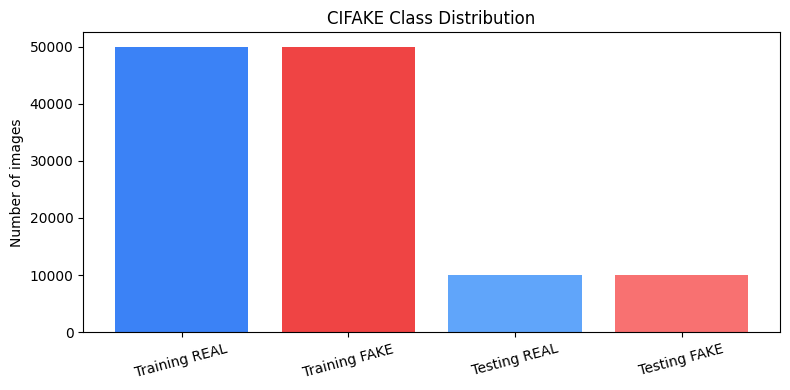

Found 100000 files belonging to 2 classes.
Using 80000 files for training.
Found 100000 files belonging to 2 classes.
Using 20000 files for validation.
Found 20000 files belonging to 2 classes.


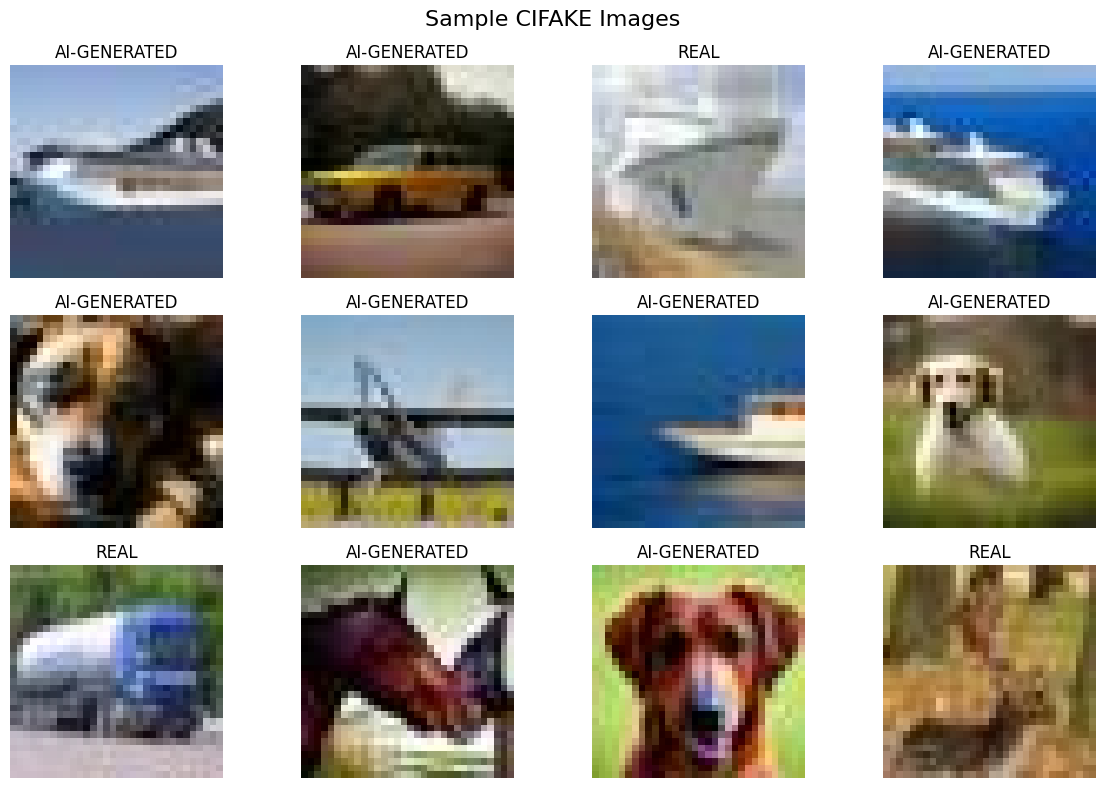

Model: "cifake_detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Rescaling)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ai_probability (Dense)          │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore")

SEED = 42
IMG_SIZE = (32, 32)
BATCH_SIZE = 128
EPOCHS = 20
VALIDATION_SPLIT = 0.20
ZIP_PATH = Path("cifake.zip")
EXTRACT_DIR = Path("cifake_data")

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/cifake.zip")
EXTRACT_DIR = Path("/content/cifake_data")

print("ZIP file exists:", ZIP_PATH.exists())

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {ZIP_PATH.resolve()}. "
        "Place cifake.zip in the same folder as this notebook."
    )

if not EXTRACT_DIR.exists():
    print("\nExtracting cifake.zip...")
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
        zip_file.extractall(EXTRACT_DIR)
    print("Dataset extracted.")
else:
    print("\nDataset has already been extracted.")


def find_dataset_folder(root, folder_name):
    for path in root.rglob("*"):
        if path.is_dir() and path.name.lower() == folder_name.lower():
            children = {child.name.lower() for child in path.iterdir() if child.is_dir()}
            if {"real", "fake"}.issubset(children):
                return path
    raise FileNotFoundError(
        f"Could not find a {folder_name} folder containing REAL and FAKE folders."
    )


TRAIN_DIR = find_dataset_folder(EXTRACT_DIR, "train")
TEST_DIR = find_dataset_folder(EXTRACT_DIR, "test")

train_subfolders = {
    folder.name.lower(): folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
}
REAL_FOLDER_NAME = train_subfolders["real"]
FAKE_FOLDER_NAME = train_subfolders["fake"]
CLASS_NAMES = [REAL_FOLDER_NAME, FAKE_FOLDER_NAME]

print("\nTraining folder:", TRAIN_DIR.resolve())
print("Testing folder:", TEST_DIR.resolve())
print("Class order:", CLASS_NAMES)
print("0 = REAL")
print("1 = FAKE / AI-generated")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}


def count_images(folder):
    return sum(
        1
        for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )


counts = {
    "Training REAL": count_images(TRAIN_DIR / REAL_FOLDER_NAME),
    "Training FAKE": count_images(TRAIN_DIR / FAKE_FOLDER_NAME),
    "Testing REAL": count_images(TEST_DIR / REAL_FOLDER_NAME),
    "Testing FAKE": count_images(TEST_DIR / FAKE_FOLDER_NAME),
}

print("\nDATASET COUNTS")
print("-" * 40)
for name, count in counts.items():
    print(f"{name + ':':16s} {count:,}")
print(f"{'Total images:':16s} {sum(counts.values()):,}")

plt.figure(figsize=(8, 4))
plt.bar(
    list(counts.keys()),
    list(counts.values()),
    color=["#3B82F6", "#EF4444", "#60A5FA", "#F87171"],
)
plt.title("CIFAKE Class Distribution")
plt.ylabel("Number of images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names=CLASS_NAMES,
    labels="inferred",
    label_mode="binary",
    validation_split=VALIDATION_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names=CLASS_NAMES,
    labels="inferred",
    label_mode="binary",
    validation_split=VALIDATION_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=CLASS_NAMES,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for index in range(min(12, len(images))):
        plt.subplot(3, 4, index + 1)
        plt.imshow(images[index].numpy().astype("uint8"))
        label = int(labels[index].numpy().item())
        plt.title("AI-GENERATED" if label == 1 else "REAL")
        plt.axis("off")
plt.suptitle("Sample CIFAKE Images", fontsize=16)
plt.tight_layout()
plt.show()

data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="reflect",
        ),
    ],
    name="data_augmentation",
)

inputs = tf.keras.Input(shape=(32, 32, 3), name="input_image")
x = data_augmentation(inputs)
x = tf.keras.layers.Rescaling(1.0 / 255, name="normalization")(x)
x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="ai_probability")(x)
model = tf.keras.Model(inputs, outputs, name="cifake_detector")

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)



Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.7607 - auc: 0.8465 - loss: 0.4878 - precision: 0.7847 - recall: 0.7197 - val_accuracy: 0.7465 - val_auc: 0.9117 - val_loss: 0.5878 - val_precision: 0.6663 - val_recall: 0.9805
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.8331 - auc: 0.9127 - loss: 0.3766 - precision: 0.8398 - recall: 0.8240 - val_accuracy: 0.7617 - val_auc: 0.9282 - val_loss: 0.5998 - val_precision: 0.6809 - val_recall: 0.9787
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.8593 - auc: 0.9348 - loss: 0.3267 - precision: 0.8638 - recall: 0.8536 - val_accuracy: 0.8464 - val_auc: 0.9568 - val_loss: 0.3638 - val_precision: 0.7779 - val_recall: 0.9666
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.8715 - auc: 0.9448 - loss: 0.3008 - precision: 0.8752 - recall: 0.8672 - val_accuracy: 0.8292 - val_auc: 0.9582 - val_loss: 0.4129 - val_precision: 0.7530 - val_recall: 0.9763
Epoch 5/20
625/625 ━━━━━

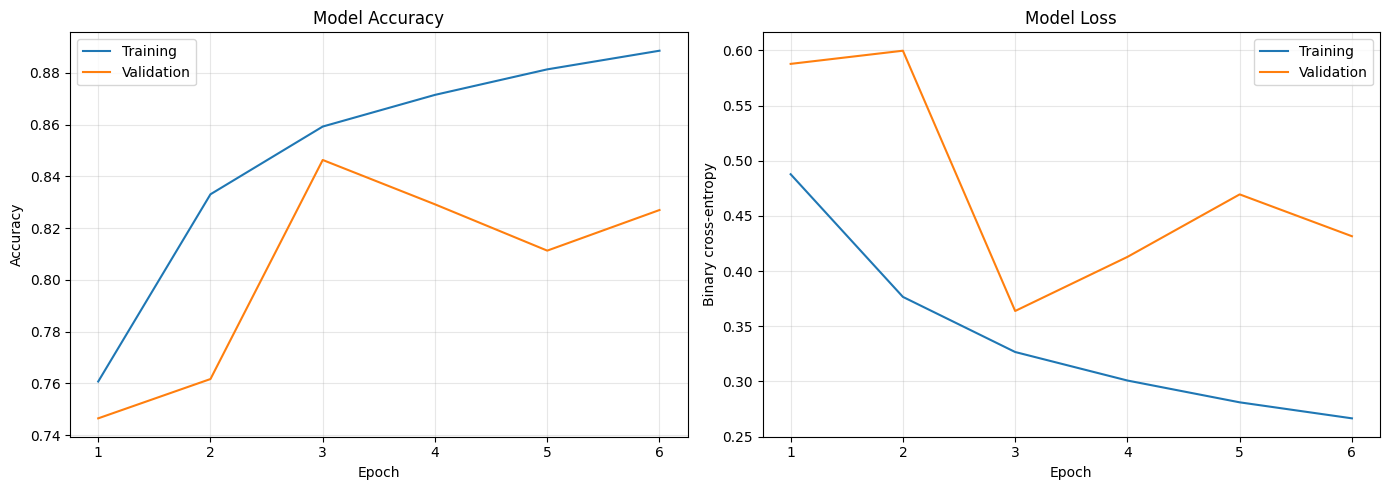


Evaluating the model on unseen test images...
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8540 - auc: 0.9575 - loss: 0.3518 - precision: 0.7888 - recall: 0.9667

TEST RESULTS
----------------------------------------
ACCURACY  : 0.8540
AUC       : 0.9575
LOSS      : 0.3518
PRECISION : 0.7888
RECALL    : 0.9667
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step

AI-GENERATED IMAGE METRICS
----------------------------------------
Precision: 0.7888
Recall:    0.9667
F1 score:  0.8687
ROC-AUC:   0.9580

CLASSIFICATION REPORT
----------------------------------------
              precision    recall  f1-score   support

        REAL     0.9570    0.7412    0.8354     10000
AI-GENERATED     0.7888    0.9667    0.8687     10000

    accuracy                         0.8539     20000
   macro avg     0.8729    0.8539    0.8521     20000
weighted avg     0.8729    0.8539    0.8521     20000



In [23]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=1,
)

epochs_completed = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_completed, history.history["accuracy"], label="Training")
plt.plot(epochs_completed, history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_completed, history.history["loss"], label="Training")
plt.plot(epochs_completed, history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nEvaluating the model on unseen test images...")
test_results = model.evaluate(test_ds, return_dict=True, verbose=1)
print("\nTEST RESULTS")
print("-" * 40)
for metric_name, metric_value in test_results.items():
    print(f"{metric_name.upper():10s}: {metric_value:.4f}")

y_true = np.concatenate(
    [labels.numpy().reshape(-1) for _, labels in test_ds]
).astype(int)
y_probability = model.predict(test_ds, verbose=1).reshape(-1)
THRESHOLD = 0.50
y_predicted = (y_probability >= THRESHOLD).astype(int)

precision = precision_score(y_true, y_predicted)
recall = recall_score(y_true, y_predicted)
f1 = f1_score(y_true, y_predicted)
roc_auc = roc_auc_score(y_true, y_probability)

print("\nAI-GENERATED IMAGE METRICS")
print("-" * 40)
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nCLASSIFICATION REPORT")
print("-" * 40)
print(
    classification_report(
        y_true,
        y_predicted,
        target_names=["REAL", "AI-GENERATED"],
        digits=4,
    )
)

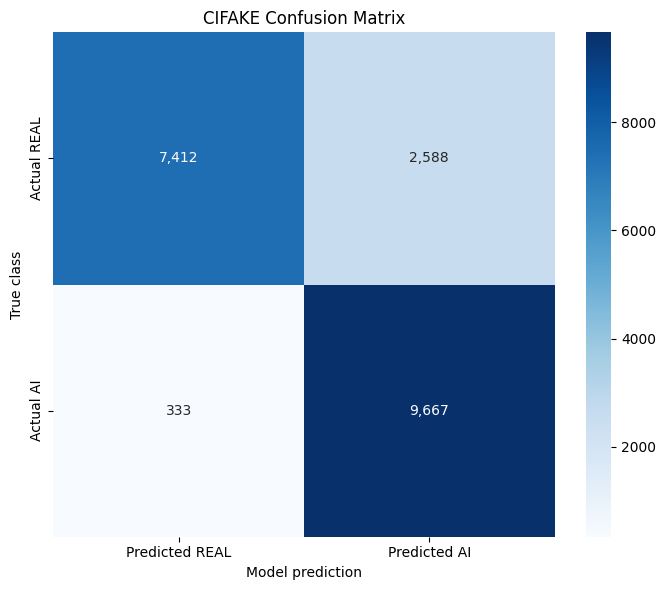


CONFUSION MATRIX BREAKDOWN
----------------------------------------
Real images correctly classified:       7,412
Real images incorrectly flagged as AI:  2,588
AI images incorrectly classified real:  333
AI images correctly detected:           9,667

Model saved as cifake_detector.keras

To test your own image, set CUSTOM_IMAGE_PATH to its filename and rerun this cell.


In [24]:
matrix = confusion_matrix(y_true, y_predicted)
plt.figure(figsize=(7, 6))
sns.heatmap(
    matrix,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Predicted REAL", "Predicted AI"],
    yticklabels=["Actual REAL", "Actual AI"],
)
plt.title("CIFAKE Confusion Matrix")
plt.xlabel("Model prediction")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

print("\nCONFUSION MATRIX BREAKDOWN")
print("-" * 40)
print(f"Real images correctly classified:       {matrix[0, 0]:,}")
print(f"Real images incorrectly flagged as AI:  {matrix[0, 1]:,}")
print(f"AI images incorrectly classified real:  {matrix[1, 0]:,}")
print(f"AI images correctly detected:           {matrix[1, 1]:,}")


def predict_image(image_path, threshold=0.50):
    """Predict whether one outside image is real or AI-generated."""
    image_path = Path(image_path)
    if not image_path.exists():
        raise FileNotFoundError(f"Could not find: {image_path.resolve()}")

    original = tf.keras.utils.load_img(image_path)
    resized = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE,
        color_mode="rgb",
    )
    image_array = tf.keras.utils.img_to_array(resized)
    image_array = np.expand_dims(image_array, axis=0)
    probability_ai = float(model.predict(image_array, verbose=0)[0][0])

    if probability_ai >= threshold:
        prediction = "AI-GENERATED"
        confidence = probability_ai
    else:
        prediction = "REAL"
        confidence = 1 - probability_ai

    print("\nCUSTOM IMAGE PREDICTION")
    print("-" * 40)
    print("Image:", image_path.name)
    print("Prediction:", prediction)
    print(f"Confidence: {confidence:.2%}")
    print(f"Probability of AI-generated: {probability_ai:.2%}")
    print(f"Probability of real: {1 - probability_ai:.2%}")

    plt.figure(figsize=(6, 6))
    plt.imshow(original)
    plt.title(f"{prediction}\nConfidence: {confidence:.2%}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    return {
        "prediction": prediction,
        "confidence": confidence,
        "ai_probability": probability_ai,
        "real_probability": 1 - probability_ai,
    }


model.save("cifake_detector.keras")
print("\nModel saved as cifake_detector.keras")

# To test an outside image after training, replace None with a filename:
# CUSTOM_IMAGE_PATH = "my_photo.jpg"
CUSTOM_IMAGE_PATH = None
if CUSTOM_IMAGE_PATH is not None:
    predict_image(CUSTOM_IMAGE_PATH)
else:
    print(
        "\nTo test your own image, set CUSTOM_IMAGE_PATH to its filename "
        "and rerun this cell."
    )